# Course Code: DT8013
# Course Name: Data Mining
# Lab Session: Timeseries Analysis

### This lab is due on the 15/10/2026.
### Save the notebook: 'yourname_timeseries.ipynb' and submit by the due date.



In this lab, you will work with time series data. We will use the basic Python library, the statsmodels library for statistical computations (https://github.com/statsmodels/statsmodels/) and the tslearn library (https://tslearn.readthedocs.io/en/stable/). 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
pd.set_option("display.max_columns",100)
from IPython.display import Image

## Data overview

This dataset contains information on the quality of the air over an undisclosed area as measured by air quallity instruments for 2 years.

In [2]:
air_data= pd.read_csv('air_quality.csv')
air_data

,Date,PT08.S1(CO),NOx(GT)
0,2004-03-10,1360.00,166.0
1,2004-03-10,1293.80,103.0
2,2004-03-10,1405.10,131.0
3,2004-03-10,1380.15,172.0
4,2004-03-10,1278.45,131.0
...,...,...,...
9352,2005-04-04,15809.85,471.7
9353,2005-04-04,15659.65,353.3
9354,2005-04-04,15640.70,293.0
9355,2005-04-04,15502.75,234.5


### Note on data pattern 
**PT08.S1(CO)** : Normal Range : 600 to 2040
                - 200 val, as missing data ( may be) 
**NOx(GT)** : Nitrogen Oxide -> Ground Truth(GT -> 0 TO 1400 ppb)

<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 1: Preprocessing (1pt)

- The index of a timeseries dataset is usually the date or time. Your task here is to convert the date column to a datetime format and set it as the index of the DataFrame.
- Clean the data as required; check if the measurements are regular or regular (measurement intervals match or not). And in case they are not, find a way to regularize them (e.g. take only one measurements per day through picking the first or last daily measurement or averaging measurements, daily). **Regularized measurements are essential for later steps.**
- Plot the two time series to visually inspect the data. What are your initial assumptions on trend, seasonality and level?

 </div>

In [3]:
#YOUR CODE HERE
    # Data samples 
print(air_data.shape)
print(air_data.dtypes)
air_data.head(10)

(9357, 3)
Date               str
PT08.S1(CO)    float64
NOx(GT)        float64
dtype: object


,Date,PT08.S1(CO),NOx(GT)
0,2004-03-10,1360.00,166.0
1,2004-03-10,1293.80,103.0
2,2004-03-10,1405.10,131.0
3,2004-03-10,1380.15,172.0
4,2004-03-10,1278.45,131.0
5,2004-03-10,1204.75,89.0
6,2004-03-11,1194.30,62.0
7,2004-03-11,1147.10,62.0
8,2004-03-11,1106.40,45.0
9,2004-03-11,1023.70,-200.0


In [4]:

 # A. Date CO -> datatime 
    # For correct ordering, time -aware slicing, resampling, time airthmetic(gaps between reading), library friendly 

DATE_COL = 'Date'  

air_raw = air_data.copy()
air_raw[DATE_COL] = pd.to_datetime(air_raw[DATE_COL])
air_raw = air_raw.set_index(DATE_COL).sort_index()

signals = air_raw.select_dtypes(include='number').columns.tolist()
print("Signals:", signals)
air_raw.head(10)

# print(air_data['Date'].dtype)    # object  -> text
# print(air_raw.index.dtype)       # datetime64[ns] -> real dates
# print(type(air_raw.index))       # DatetimeIndex

Signals: ['PT08.S1(CO)', 'NOx(GT)']


,PT08.S1(CO),NOx(GT)
Date,,
2004-03-10,1360.00,166.0
2004-03-10,1293.80,103.0
2004-03-10,1405.10,131.0
2004-03-10,1380.15,172.0
2004-03-10,1278.45,131.0
2004-03-10,1204.75,89.0
2004-03-11,1194.30,62.0
2004-03-11,1147.10,62.0
2004-03-11,1106.40,45.0


In [5]:
# B . Clean Up logic and regularized data 
    # 1. Check for irregular data 
print("Duplicate timestamps:", air_raw.index.duplicated().sum())
gaps = air_raw.index.to_series().diff().dropna()
print("\nGaps Occurs at:\n", gaps.value_counts().head(10))
print("\nMin gap:", gaps.min())
print("Max gap:", gaps.max())

    # 2. How many reading each day ?
print('\nReading per day:')
print(air_raw.groupby(air_raw.index.date).size().value_counts().head())


Duplicate timestamps: 8966

Gaps Occurs at:
 Date
0 days    8966
1 days     390
Name: count, dtype: int64

Min gap: 0 days 00:00:00
Max gap: 1 days 00:00:00

Reading per day:
24    389
6       1
15      1
Name: count, dtype: int64


In [6]:
# 3. Check the days having 6 and 15 datas 
counts = air_raw.groupby(air_raw.index).size()
print(counts.head(2)); print(counts.tail(2))

# 4. Trim and keep full days only 
full_days = counts[counts == 24].index
air_raw = air_raw[air_raw.index.isin(full_days)]

# 5. Check again 
print('\nReading per day after trim odds:')
print(air_raw.groupby(air_raw.index.date).size().value_counts().head())

Date
2004-03-10     6
2004-03-11    24
dtype: int64
Date
2005-04-03    24
2005-04-04    15
dtype: int64

Reading per day after trim odds:
24    389
Name: count, dtype: int64


In [7]:
# 6. Evaluate missing values 
print('Missing values: ', air_raw.isna().sum())
print('\nInvalid values: ', air_raw[signals].describe())

Missing values:  PT08.S1(CO)    0
NOx(GT)        0
dtype: int64

Invalid values:          PT08.S1(CO)      NOx(GT)
count   9336.000000  9336.000000
mean    8292.555927   168.475653
std     4174.028045   257.567336
min      612.200000  -200.000000
25%     4584.762500    50.000000
50%     8289.450000   141.000000
75%    11853.187500   284.200000
max    15919.650000  1479.000000


In [8]:
# 6.1 : Negative ,min values notices, invalid value
# Check : how many datas have -ve value 
print('Datas with invalid values:\n')
print((air_raw[signals] < 0).sum())

# Check : which -ve values are there?
print('\n List of invalid values')
for col in signals:
    print(col)
    print(air_raw.loc[air_raw[col] < 0, col].value_counts())

# Replace: 1639, Nox(GT) found to be invalid 
air_raw[signals] = air_raw[signals].replace(-200, np.nan)
print('\nDatas with invalid values after replace:')
print((air_raw[signals] < 0).sum())

Datas with invalid values:

PT08.S1(CO)       0
NOx(GT)        1639
dtype: int64

 List of invalid values
PT08.S1(CO)
Series([], Name: count, dtype: int64)
NOx(GT)
NOx(GT)
-200.0    1639
Name: count, dtype: int64

Datas with invalid values after replace:
PT08.S1(CO)    0
NOx(GT)        0
dtype: int64


In [9]:
# 7. Regularize : one value per day 
air_daily = air_raw[signals].resample('D').mean() #group the rows by calender day 
print("Days with no value reading...")
print(air_daily.isna().sum())      # days with no valid reading at all = 34 NOx 

# 8. Fill those remaining gaps
air_daily = air_daily.interpolate(method='time', limit_direction='both')

# 9. Final check: regular, no NaN
print("\nData Regular Status:", air_daily.index.to_series().diff().dropna().nunique() == 1)
print("Number of Invalid Data after Regularization :", air_daily.isna().sum().sum())

Days with no value reading...
PT08.S1(CO)     0
NOx(GT)        34
dtype: int64

Data Regular Status: True
Number of Invalid Data after Regularization : 0


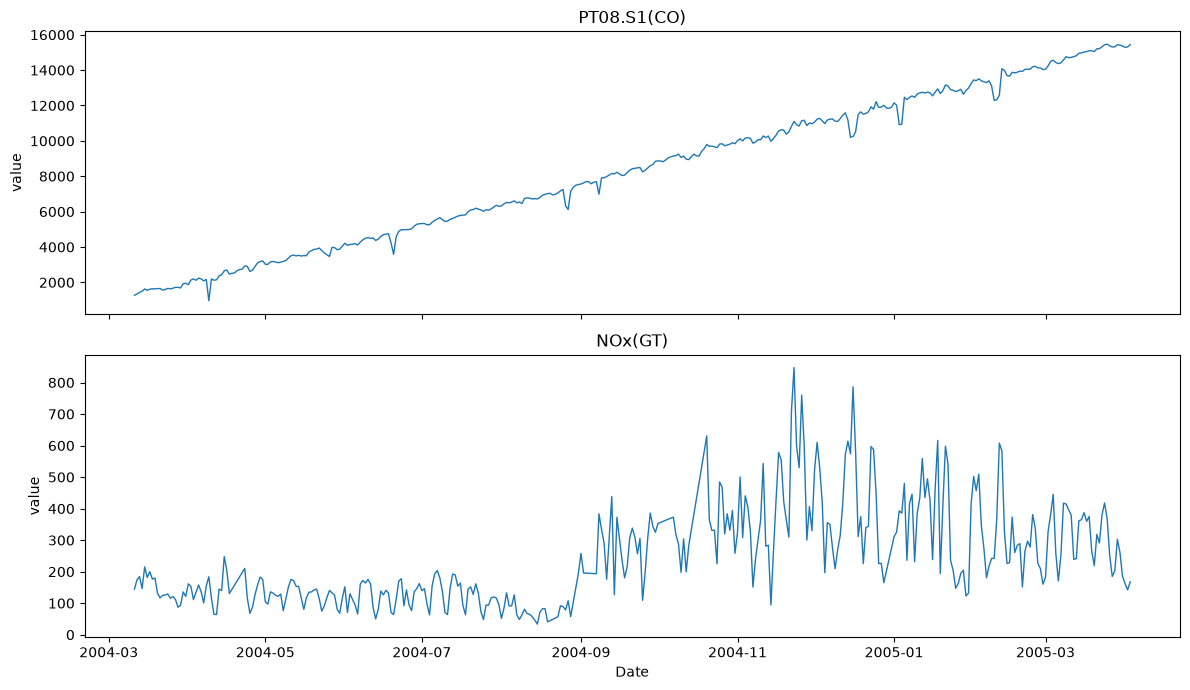

In [10]:
# 10. Plot the signal
fig, axes = plt.subplots(len(signals), 1, figsize=(12, 3.5 * len(signals)), sharex=True)

for ax, col in zip(np.atleast_1d(axes), signals):
    ax.plot(air_daily.index, air_daily[col], linewidth=1)
    ax.set_title(col)
    ax.set_ylabel('value')

plt.xlabel('Date')
plt.tight_layout()
plt.show()

### Data Finding 
### PT08.S1(CO)
1. **Trend:** Upward and almost linear trend.
2. **Seasonality:** Regular Dips, regualr pattern (weekend effect, not sure)
2. **Level:** Not stable. Mean seems to be moving with the trend. 
### Nox(GT)
1. **Trend:** No confirm stable trend
2.  **Seasonality:**  Nothing can be claimed here as most data probaby filled with noise.
3.  **Level:** March 2024 to Sept 2004 : Vlaues stays between : 100 to 200 while Afterward : Values betweem : 300 to 800.
3. **Variance:** Ups and Down is consistent with higher level : `Not Constant Variance`


 ## Timeseries Components and Seasonal decomposition

A timeseries signal is composed of the trend, seasonality, level and the presence of outliers.

Seasonal decomposition is based on the concept that a timeseries signal is made up of several components added or multiplied together. These underlying components are usually the trend, seasonality and residuals. Seasonal decomposition helps us to better understand the underlying patterns in a timeseries signal.

##### Additive: y(t) = Trend + Seasonality + Residuals
##### Multiplicative: y(t) = Trend * Seasonality * Residuals

The additive model is applied in seasonal decomposition when the seasonal variation remains relatively stable over time, whereas the multiplicative model is utilised when the seasonal variation escalates as time progresses.

We make use of the statsmodels package to achieve this. You can read more about the stats model package here: https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html

<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 2 (1pt)

- Decompose the time series into trend, seasonal, and residual components.
- Plot the decomposed components to understand the underlying patterns.
- Were your assumptions in Task 1 correct?

 </div>

In [11]:
## YOUR CODE HERE
    # Assuming seasonal cycle as weekly
PERIOD = 7
    # Also for multiplicative model all values must be greater than 0 
print('Minimum Value:\n', air_daily.min())
    # If weekly investigation to be choosen there must have 2 full cycle
print("number of")
print(len(air_daily), "days")

Minimum Value:
 PT08.S1(CO)    963.258333
NOx(GT)         33.608696
dtype: float64
number of
389 days


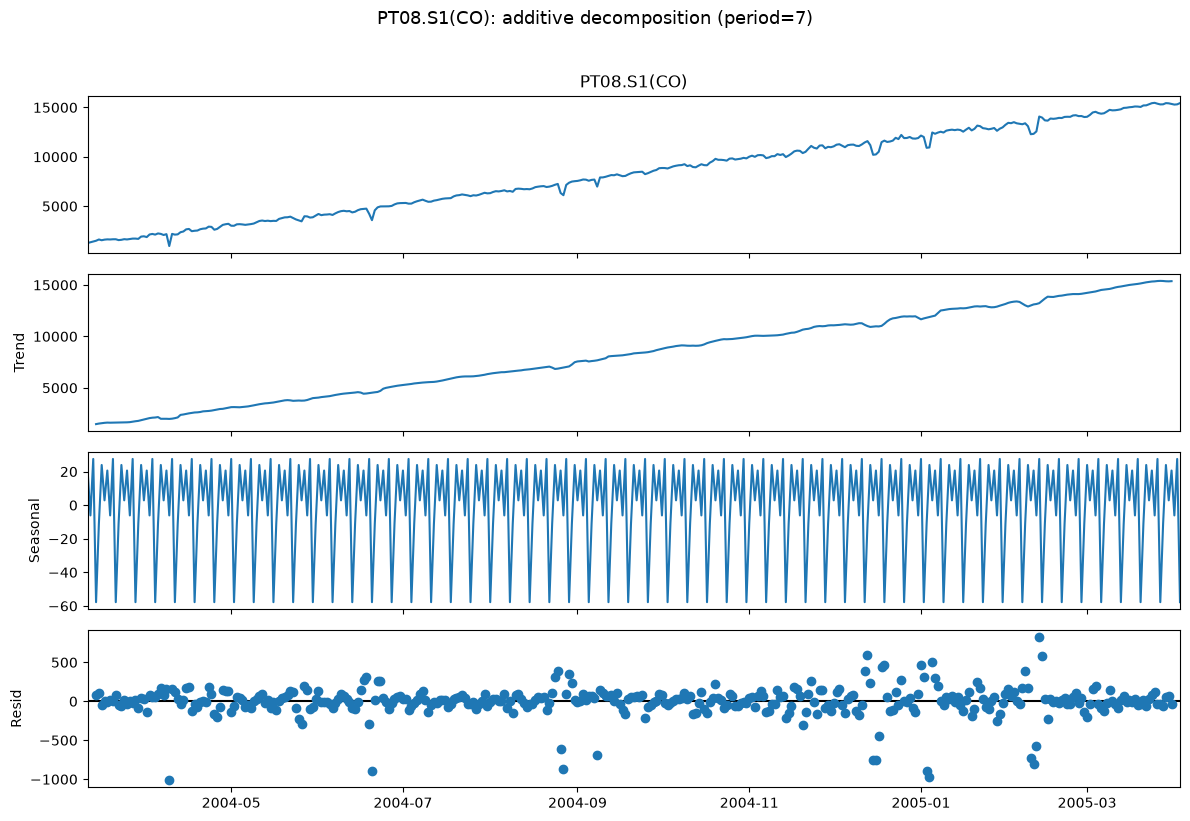

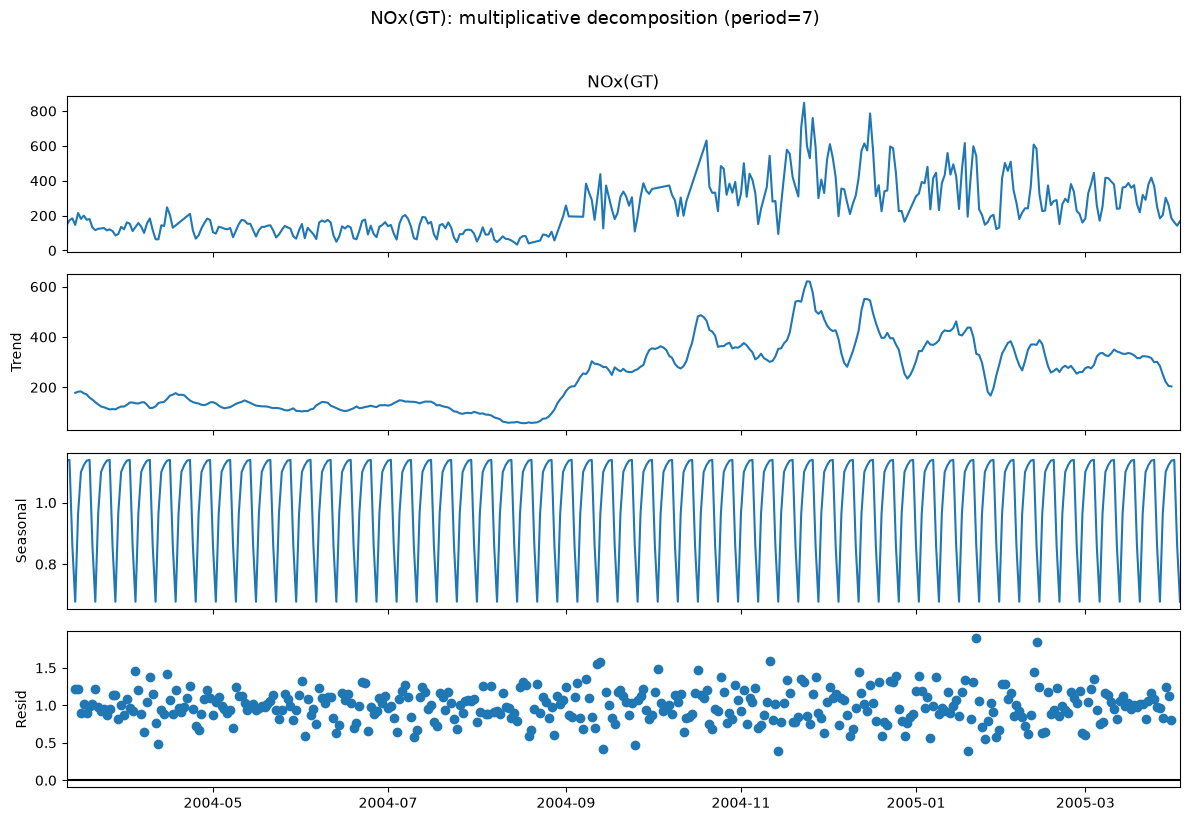

In [12]:
# 2. Signal Decompostion
from statsmodels.tsa.seasonal import seasonal_decompose
co  = air_daily['PT08.S1(CO)']
nox = air_daily['NOx(GT)']

# Task 1 hypothesis: CO additive cz of not stable level, NOx multiplicative cz of not constant variance
co_add  = seasonal_decompose(co,  model='additive',       period=PERIOD)  
nox_mul = seasonal_decompose(nox, model='multiplicative', period=PERIOD)


def plot_decomp(result, title):
    fig = result.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle(title, y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

plot_decomp(co_add,  'PT08.S1(CO): additive decomposition (period=7)')
plot_decomp(nox_mul, 'NOx(GT): multiplicative decomposition (period=7)')

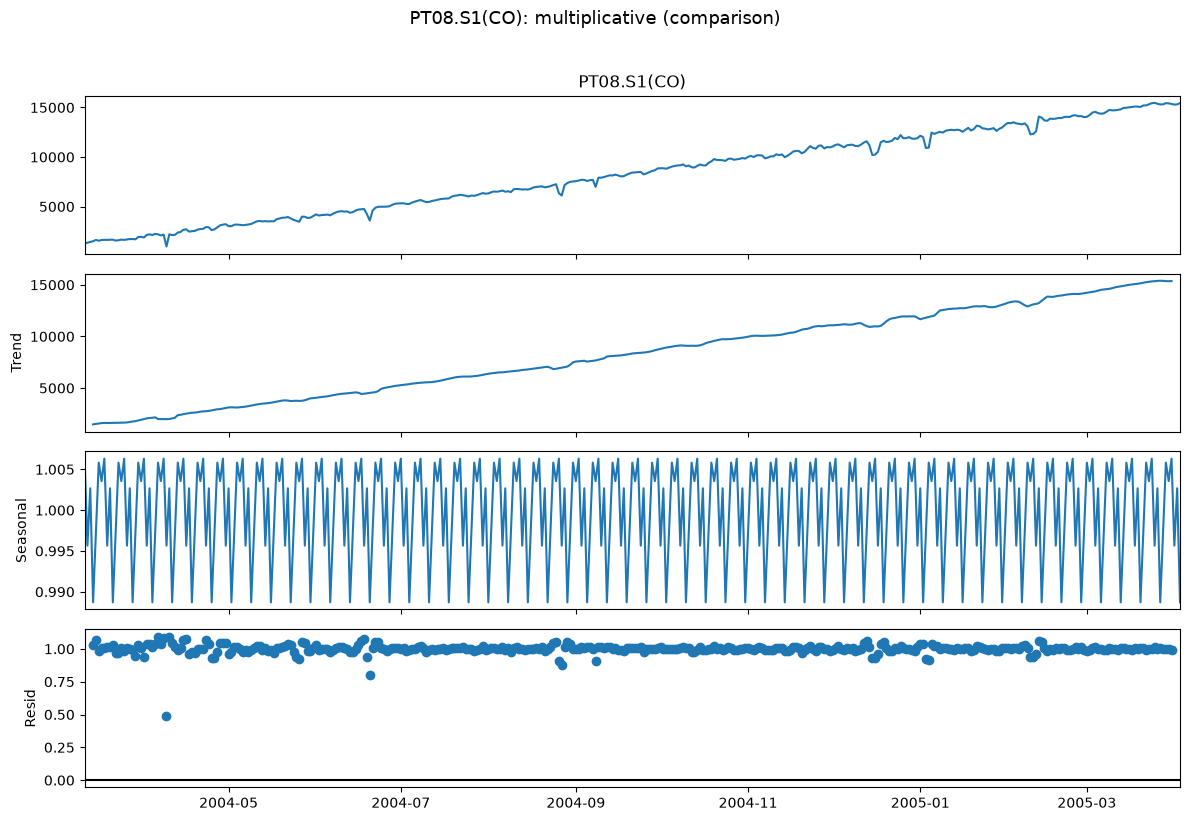

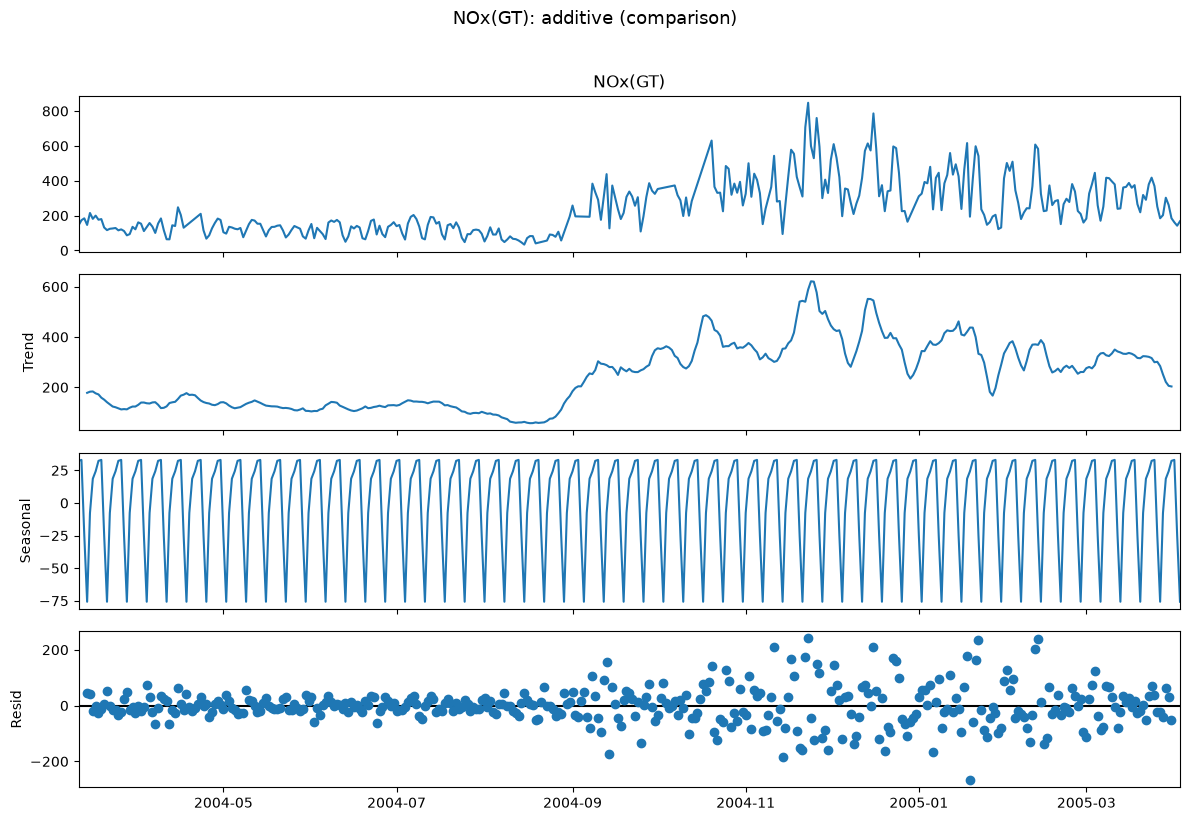

In [13]:
# The other model for each, for comparison 
co_mul  = seasonal_decompose(co,  model='multiplicative', period=PERIOD)
nox_add = seasonal_decompose(nox, model='additive',       period=PERIOD)

plot_decomp(co_mul,  'PT08.S1(CO): multiplicative (comparison)')
plot_decomp(nox_add, 'NOx(GT): additive (comparison)')

### Were the hypothesis correct ?
**PT08.S1(CO): mostly correct**
1. **Trend (correct):**The trend component is an almost straight line.
2. **Level (correct):** The level is not stable and follows the trend, so the signal is expected to be non-stationary.
3. **Seasonality (partly):** I assumed a weekly pattern from the small dips. A weekly component exists but is very small (about -58 to +28 in the additive model, or about -1% to +0.6% in the multiplicative one). The visible dips are irregular events that appear as large outliers in the residuals, not a seasonal pattern.


**NOx(GT): correct**
1. **trend (correct):**The trend component is low (about 100-150) until August 2004, then rises sharply to a peak of about 600 and stays higher afterwards, thus no fixed stable trend.
2. **Seasonality (correct):** A clear weekly pattern exists, with the weekly low about 33% below the trend and the high about 15% above it.
3. **Variance and Model (multiplicative, confirmed):** In the additive fit, the residuals widen as the level rises (about ±30-50 before September, about ±150-250 after). In the multiplicative fit, the residuals stay around 1 with a constant spread. The seasonal effect therefore scales with the level.

## Stationarity Test using the Augmented Dickey-Fuller (ADF) Test

The ADF test is commonly used to check for stationarity in a timeseries. A stationary time series is one in which its statistical characteristics, including mean, variance, covariance, and standard deviation, remain constant over time.
We usually employ the statsmodel package for this task. You can read more about it here:https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.adfuller.html

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 3 (2pt)
- Are the signals stationary? Use the Augmented Dickey-Fuller test to determine whether the two time series signals from the previous tasks are stationary or not. Report the p_value obtained for each of the signals

- If the series is not stationary, apply an appropriate method to make it stationary.

 </div>


In [14]:
## YOUR CODE HERE
# 1. Helper function 
from statsmodels.tsa.stattools import adfuller

co  = air_daily['PT08.S1(CO)']
nox = air_daily['NOx(GT)']

def adf_report(series, name, regression='c'):
    stat, p, usedlag, nobs, crit, _ = adfuller(series.dropna(), regression=regression, autolag='AIC')
    print(f"====== {name} (regression='{regression}') =====")
    print(f"ADF statistic : {stat:.4f}")
    print(f"p-value       : {p:.4f}")
    print(f"Lags used     : {usedlag} | Observations: {nobs}")
    for k, v in crit.items():
        print(f"Critical {k:>3}: {v:.4f}")
    print("Result        :", "STATIONARY (reject H0)" if p < 0.05 else "NON-STATIONARY (cannot reject H0)")
    print()
    return p

In [15]:
# 2. Originall signal stationary status 
p_co_orig  = adf_report(co,  'CO original') # regression ct -> stationary !
p_nox_orig = adf_report(nox, 'NOx original')

====== CO original (regression='c') =====
ADF statistic : 0.2388
p-value       : 0.9744
Lags used     : 11 | Observations: 377
Critical  1%: -3.4478
Critical  5%: -2.8692
Critical 10%: -2.5709
Result        : NON-STATIONARY (cannot reject H0)

====== NOx original (regression='c') =====
ADF statistic : -1.8482
p-value       : 0.3568
Lags used     : 12 | Observations: 376
Critical  1%: -3.4479
Critical  5%: -2.8693
Critical 10%: -2.5709
Result        : NON-STATIONARY (cannot reject H0)



C:\Users\sahbi\AppData\Local\Temp\ipykernel_32580\902267644.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, usedlag, nobs, crit, _ = adfuller(series.dropna(), regression=regression, autolag='AIC')
C:\Users\sahbi\AppData\Local\Temp\ipykernel_32580\902267644.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, usedlag, nobs, crit, _ = adfuller(series.dr

In [16]:
# 3. Both are non - stationary, apply transformation and retest 

# CO: trend only -> first difference
co_diff = co.diff().dropna()

# NOx: growing variance + level shift -> log, then first difference
nox_log      = np.log(nox)
nox_log_diff = nox_log.diff().dropna()

p_co_diff  = adf_report(co_diff,       'CO first difference')
p_nox_ldiff = adf_report(nox_log_diff, 'NOx log + first difference')

====== CO first difference (regression='c') =====
ADF statistic : -10.1635
p-value       : 0.0000
Lags used     : 10 | Observations: 377
Critical  1%: -3.4478
Critical  5%: -2.8692
Critical 10%: -2.5709
Result        : STATIONARY (reject H0)

====== NOx log + first difference (regression='c') =====
ADF statistic : -6.1101
p-value       : 0.0000
Lags used     : 17 | Observations: 370
Critical  1%: -3.4481
Critical  5%: -2.8694
Critical 10%: -2.5709
Result        : STATIONARY (reject H0)



C:\Users\sahbi\AppData\Local\Temp\ipykernel_32580\902267644.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, usedlag, nobs, crit, _ = adfuller(series.dropna(), regression=regression, autolag='AIC')
C:\Users\sahbi\AppData\Local\Temp\ipykernel_32580\902267644.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, usedlag, nobs, crit, _ = adfuller(series.dr

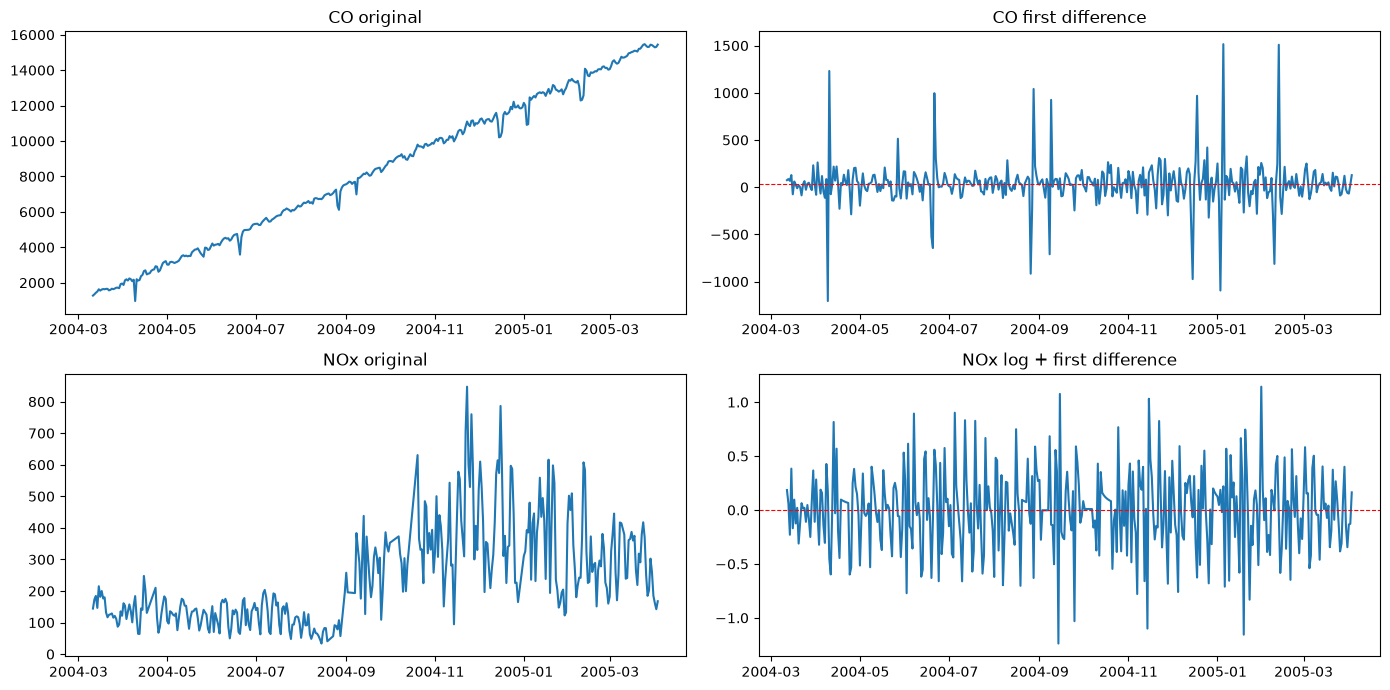

In [17]:
# 4. Plot the before and after impact 
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

axes[0, 0].plot(co);            axes[0, 0].set_title('CO original')
axes[0, 1].plot(co_diff);       axes[0, 1].set_title('CO first difference')
axes[1, 0].plot(nox);           axes[1, 0].set_title('NOx original')
axes[1, 1].plot(nox_log_diff);  axes[1, 1].set_title('NOx log + first difference')

axes[0, 1].axhline(co_diff.mean(), color='red', linestyle='--', linewidth=0.8)
axes[1, 1].axhline(nox_log_diff.mean(), color='red', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.show()

## Forecasting 

Forecasting a timeseries involves making predictions on future values. The different types of models for forecasting time series data include: 

##### Statistical Methods include Exponential Smoothing, AR, MA, ARIMA, SARIMA, ARMA,
##### State-space models include Kalman filter, HMMs, 
##### Deep learning models include RNNs, CNNs and LSTMs.


<div class='alert alert-block alert-success' style="font-weight:bolder">
    
### Task 4 (2pt)
In this task, we will work with time series forecasting.
- Split each time series into a training set and a test set.
- Use the training set to fit your models and the test set to evaluate prediction performance.
- Next, use two different methods to forecast the values of the two time series signals for the next 90 days from the last date.
- Remember to take into account the assumptions of a method before using it.
- If your methods have hyperparameters. Show how you obtained the optimal hyperparameters.
- Quantitatively evaluate model performance (MAE, RMSE, etc)
- Visualise the forecasted values.


 </div>

In [18]:
## YOUR CODE HERE
# 1. Setup and data split 
import itertools, warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

H = 90   # test size + forcast period

co      = air_daily['PT08.S1(CO)']
nox     = air_daily['NOx(GT)']
nox_log = np.log(nox)

# chronological split: last 90 days = test
co_train,  co_test  = co.iloc[:-H],  co.iloc[-H:]
nox_train, nox_test = nox.iloc[:-H], nox.iloc[-H:]
nox_log_train       = nox_log.iloc[:-H]

print("Train:", co_train.index[0].date(), "->", co_train.index[-1].date(), f"({len(co_train)} days)")
print("Test :", co_test.index[0].date(),  "->", co_test.index[-1].date(),  f"({len(co_test)} days)")

Train: 2004-03-11 -> 2005-01-03 (299 days)
Test : 2005-01-04 -> 2005-04-03 (90 days)


In [19]:
# 2. Method choice : Hot-Winters and SARIMA
# Helpers : to generate the baseline for comparision 

def metrics(y_true, y_pred):
    err = np.asarray(y_true) - np.asarray(y_pred)
    return {'MAE': np.abs(err).mean(), 'RMSE': np.sqrt((err ** 2).mean())}

def seasonal_naive(train, h, period=7):
    # repeat the last 7 observed days over the horizon
    reps = int(np.ceil(h / period))
    return np.tile(train.iloc[-period:].values, reps)[:h]

co_naive  = seasonal_naive(co_train,  H)
nox_naive = seasonal_naive(nox_train, H)

In [20]:
# 3. Holt - Winter hyperparameter search 
def fit_hw(y, damped, seasonal):
    seas = None if seasonal == 'none' else seasonal
    return ExponentialSmoothing(
        y, trend='add', damped_trend=damped,
        seasonal=seas, seasonal_periods=7 if seas else None,
        initialization_method='estimated'
    ).fit()

def hw_search(y, seasonals):
    rows = []
    for damped, seas in itertools.product([False, True], seasonals):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                m = fit_hw(y, damped, seas)
            rows.append({'damped': damped, 'seasonal': seas, 'AIC': m.aic})
        except Exception as e:
            print("failed:", damped, seas, e)
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

hw_co_tab  = hw_search(co_train,       ['none', 'add', 'mul'])
hw_nox_tab = hw_search(nox_log_train,  ['none', 'add'])   # log scale: additive seasonality = multiplicative on raw

print("CO Holt-Winters (lower AIC = better)"); print(hw_co_tab.round(1)); print()
print("NOx (log) Holt-Winters");               print(hw_nox_tab.round(1))


# 3.2. Fit the best Holt-Winters
hw_co_cfg  = (hw_co_tab.loc[0, 'damped'],  hw_co_tab.loc[0, 'seasonal'])
hw_nox_cfg = (hw_nox_tab.loc[0, 'damped'], hw_nox_tab.loc[0, 'seasonal'])
print("CO best config :", hw_co_cfg) #damped = true -> flattened 
print("NOx best config:", hw_nox_cfg)

co_hw_pred  = fit_hw(co_train, *hw_co_cfg).forecast(H)
nox_hw_pred = np.exp(fit_hw(nox_log_train, *hw_nox_cfg).forecast(H))   # back to original units

CO Holt-Winters (lower AIC = better)
   damped seasonal     AIC
0   False     none  3243.4
1   False      add  3245.4
2    True     none  3246.4
3    True      add  3249.8
4   False      mul  3251.0
5    True      mul  3254.2

NOx (log) Holt-Winters
   damped seasonal    AIC
0   False      add -729.8
1    True      add -727.7
2   False     none -609.7
3    True     none -607.7
CO best config : (np.False_, 'none')
NOx best config: (np.False_, 'add')


In [21]:
# 4. SARIMA tuning 
def fit_sarima(y, p, q, P, Q, trend):
    tr = None if trend == 'none' else trend
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return SARIMAX(y, order=(int(p), 1, int(q)),
                       seasonal_order=(int(P), 0, int(Q), 7),
                       trend=tr).fit(disp=False, maxiter=200)

def sarima_search(y):
    rows = []
    for p, q, P, Q, tr in itertools.product(range(3), range(3), range(2), range(2), ['none', 'c']):
        try:
            m = fit_sarima(y, p, q, P, Q, tr)
            rows.append({'p': p, 'q': q, 'P': P, 'Q': Q, 'trend': tr, 'AIC': m.aic})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

sar_co_tab  = sarima_search(co_train)       
sar_nox_tab = sarima_search(nox_log_train)

print("CO SARIMA top 5");        print(sar_co_tab.head().round(1)); print()
print("NOx (log) SARIMA top 5"); print(sar_nox_tab.head().round(1))



CO SARIMA top 5
   p  q  P  Q trend     AIC
0  2  1  0  0     c  4026.3
1  1  2  0  0     c  4027.0
2  2  1  1  0     c  4028.3
3  2  1  0  1     c  4028.3
4  1  1  0  0     c  4029.8

NOx (log) SARIMA top 5
   p  q  P  Q trend    AIC
0  1  1  1  1  none  107.4
1  1  2  1  1  none  108.9
2  2  1  1  1  none  108.9
3  2  2  1  1  none  110.8
4  2  1  1  1     c  110.9


In [22]:
# 4.2. Fitting Sarima model 
sar_co_cfg  = sar_co_tab.loc[0,  ['p', 'q', 'P', 'Q', 'trend']].tolist()
sar_nox_cfg = sar_nox_tab.loc[0, ['p', 'q', 'P', 'Q', 'trend']].tolist()
print("CO best  [p,q,P,Q,trend]:", sar_co_cfg)
print("NOx best [p,q,P,Q,trend]:", sar_nox_cfg)

co_sar_pred  = fit_sarima(co_train, *sar_co_cfg).forecast(H)
nox_sar_pred = np.exp(fit_sarima(nox_log_train, *sar_nox_cfg).forecast(H))

CO best  [p,q,P,Q,trend]: [np.int64(2), np.int64(1), np.int64(0), np.int64(0), 'c']
NOx best [p,q,P,Q,trend]: [np.int64(1), np.int64(1), np.int64(1), np.int64(1), 'none']


In [23]:
# 5. Evaluation on test data 

rows = []
for sig, y_true, preds in [
    ('CO',  co_test,  {'Seasonal naive': co_naive,  'Holt-Winters': co_hw_pred,  'SARIMA': co_sar_pred}),
    ('NOx', nox_test, {'Seasonal naive': nox_naive, 'Holt-Winters': nox_hw_pred, 'SARIMA': nox_sar_pred}),
]:
    for name, pred in preds.items():
        rows.append({'Signal': sig, 'Method': name, **metrics(y_true, pred)})

results = pd.DataFrame(rows)
print(results.round(2).to_string(index=False))


Signal         Method     MAE    RMSE
    CO Seasonal naive 2049.88 2311.01
    CO   Holt-Winters 1151.50 1186.35
    CO         SARIMA  330.02  378.18
   NOx Seasonal naive  135.55  162.77
   NOx   Holt-Winters  170.95  195.93
   NOx         SARIMA   94.80  117.33


**Analysis**
MAE and RMSE show how large errors in the forecast, but in which direction cannot be conifrmed here. 
**CO: Acceptable**
1. **Baseline** is large because CO follows updward trend
2. **Holt-Winters:** RMS and MAE are close to each other both in HW and SARIMA. It may be because CO's slope have increased over time. Thus check direction of the prediction trend can clarify it.
3. **Model Error:** Both model error is smaller than the baseline which is good. 

**NOx: Acceptable but strange for HW**
1. **SARIMA Performs better:** 30% better than baseline 
2. **Holt-Winters:** It's MAE is goes higher than the baseline. It looses and performs worse here. I an not sure about why this happen but I believe this may be because NOx has no fixed trend, so the slove on the training data might have influenced it. 

**Conclusion:** Both test suggest that SARIMA performs well on both variables. However, NOx is hard to predict because of it's daily noise and unprecedented shift.

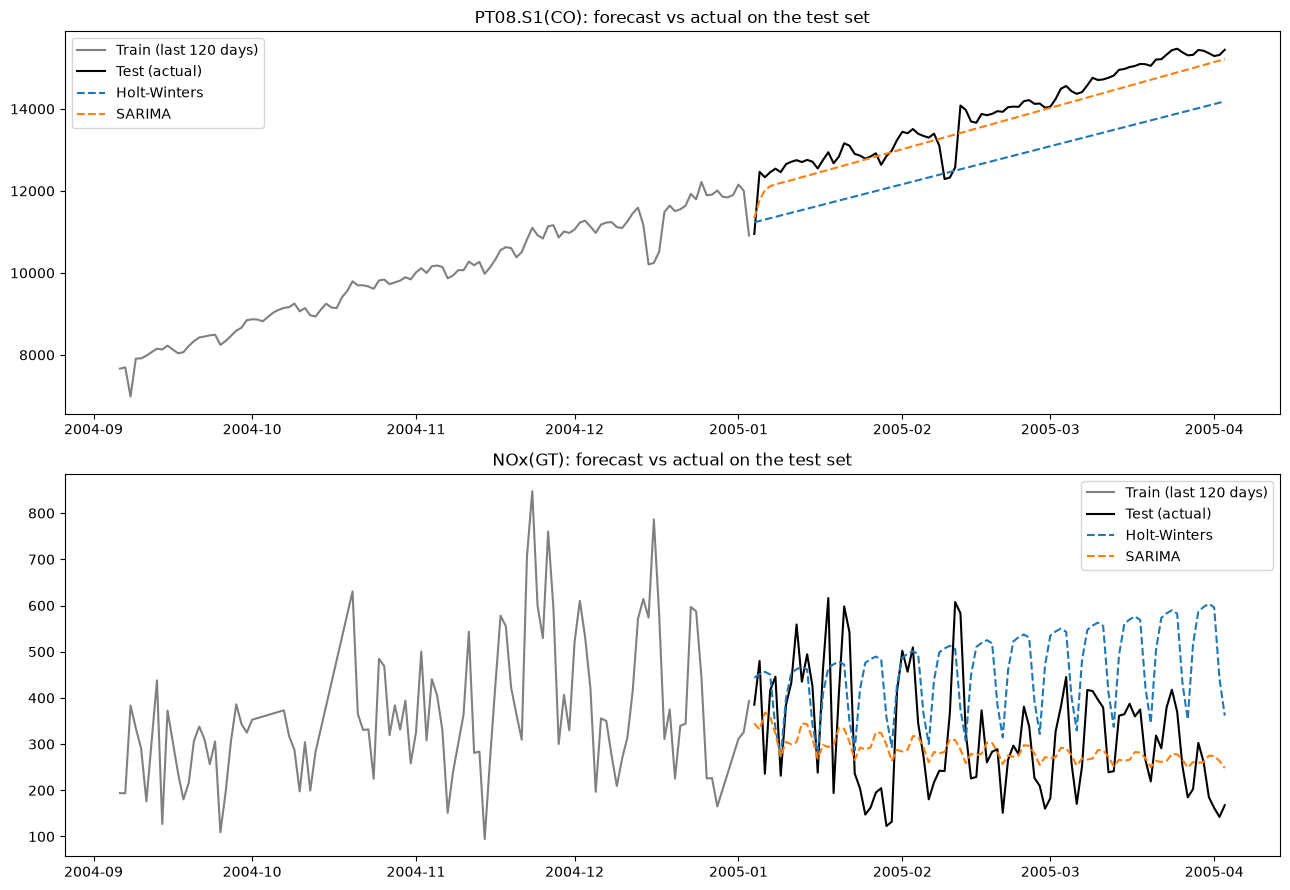

In [24]:
# 6. Plot forecast 

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

for ax, name, train, test, hw, sar in [
    (axes[0], 'PT08.S1(CO)', co_train,  co_test,  co_hw_pred,  co_sar_pred),
    (axes[1], 'NOx(GT)',     nox_train, nox_test, nox_hw_pred, nox_sar_pred),
]:
    ax.plot(train.index[-120:], train.iloc[-120:], label='Train (last 120 days)', color='gray')
    ax.plot(test.index, test, label='Test (actual)', color='black')
    ax.plot(test.index, np.asarray(hw),  label='Holt-Winters', linestyle='--')
    ax.plot(test.index, np.asarray(sar), label='SARIMA',       linestyle='--')
    ax.set_title(f'{name}: forecast vs actual on the test set')
    ax.legend()

plt.tight_layout()
plt.show()

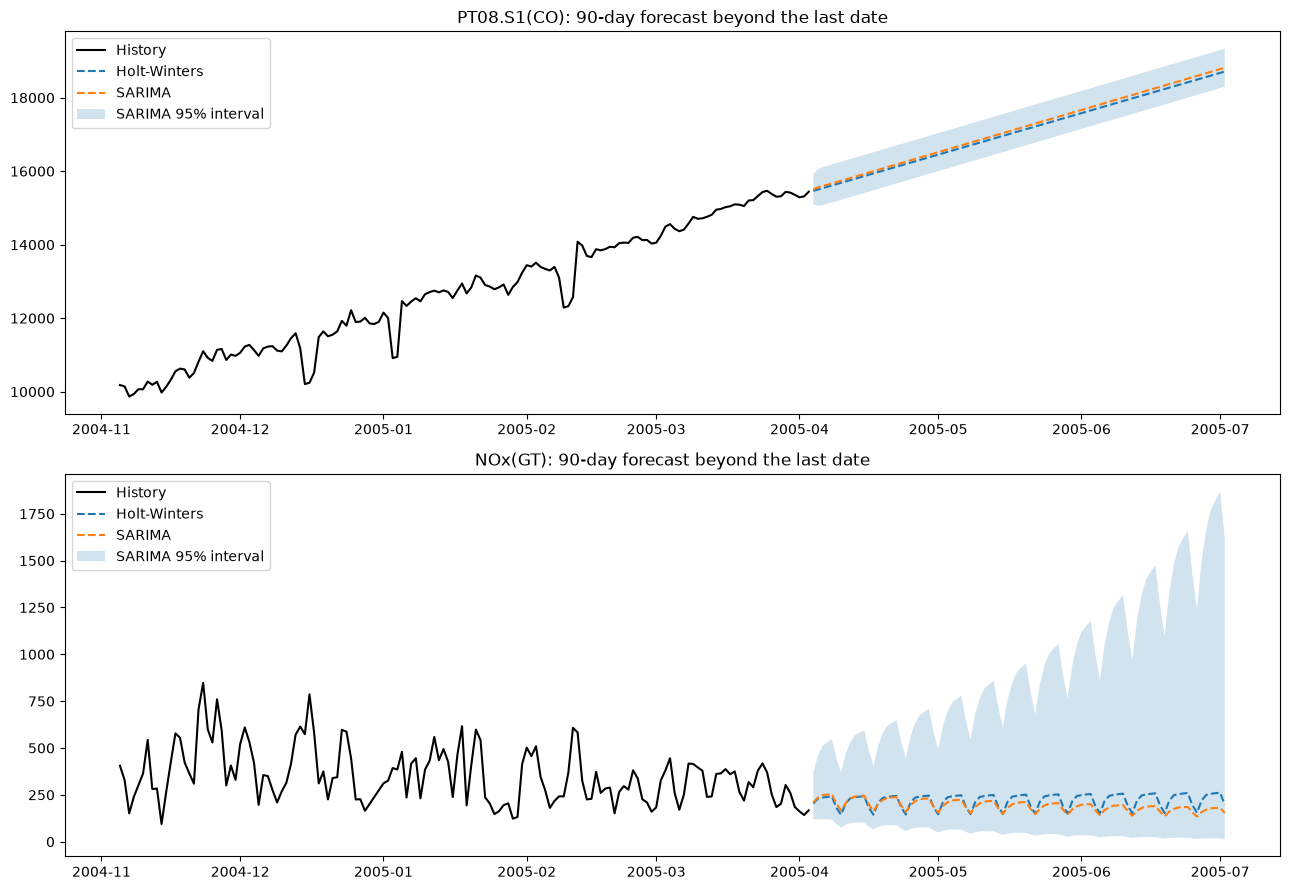

In [25]:
# 7. forcast 90 days 
future_idx = pd.date_range(co.index[-1] + pd.Timedelta(days=1), periods=H, freq='D')

# Holt-Winters 
co_fut_hw  = pd.Series(fit_hw(co,      *hw_co_cfg).forecast(H).values,           index=future_idx)
nox_fut_hw = pd.Series(np.exp(fit_hw(nox_log, *hw_nox_cfg).forecast(H).values),  index=future_idx)

# SARIMA with 95% intervals
    # that is for every 95 out 100 future data falls in the band
co_res  = fit_sarima(co,      *sar_co_cfg).get_forecast(H)
nox_res = fit_sarima(nox_log, *sar_nox_cfg).get_forecast(H)

co_fut_sar  = pd.Series(co_res.predicted_mean.values, index=future_idx)
co_ci       = pd.DataFrame(co_res.conf_int().values, index=future_idx)

nox_fut_sar = pd.Series(np.exp(nox_res.predicted_mean.values), index=future_idx)
nox_ci      = pd.DataFrame(np.exp(nox_res.conf_int().values), index=future_idx)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))
for ax, name, hist, hw, sar, ci in [
    (axes[0], 'PT08.S1(CO)', co,  co_fut_hw,  co_fut_sar,  co_ci),
    (axes[1], 'NOx(GT)',     nox, nox_fut_hw, nox_fut_sar, nox_ci),
]:
    ax.plot(hist.index[-150:], hist.iloc[-150:], color='black', label='History')
    ax.plot(hw.index,  hw,  linestyle='--', label='Holt-Winters')
    ax.plot(sar.index, sar, linestyle='--', label='SARIMA')
    ax.fill_between(ci.index, ci[0], ci[1], alpha=0.2, label='SARIMA 95% interval')
    ax.set_title(f'{name}: 90-day forecast beyond the last date')
    ax.legend()
plt.tight_layout()
plt.show()

## Timeseries Clustering
Time series clustering is about grouping time series that behave similarly. It’s a type of unsupervised learning, meaning we don’t have labels or categories beforehand. The goal is to discover hidden patterns or structures in the data by looking at how the time series change over time.

In [27]:
Image("./Images/clusters.png")

FileNotFoundError: No such file or directory: './Images/clusters.png'

FileNotFoundError: No such file or directory: './Images/clusters.png'

<IPython.core.display.Image object>

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 5 (2pt)

- For each day in the dataset, extract and keep only the first 6 readings for each signal.
- For each of the two signals, perform clustering twice:
    - Using Time Series K-Means with Dynamic Time Warping (DTW).
    - Using Time Series K-Means with Euclidean distance.
- Plot the clustered time series for each method, showing the cluster centers.
- Quantitatively evaluate the cluster quality (e.g., using silhouette score, etc.).
- How does the clustering differ under DTW vs Euclidean? Why?
  
Hint: The tslearn library has a time series clustering method. Pay attention to how the data must be formatted before clustering.

 </div>

In [ ]:
#YOUR CODE HERE
# 1. Data preparation 

from tslearn.clustering import TimeSeriesKMeans, silhouette_score
from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from sklearn.metrics import adjusted_rand_score

N_READ = 6

def first_n_windows(df, col, n=N_READ):
    rows, days = [], []
    for day, s in df[col].groupby(df.index):
        v = s.values[:n]
        if len(v) == n:
            rows.append(v)
            days.append(day)
    return pd.DataFrame(rows, index=days)

windows = {
    'CO':  first_n_windows(air_raw, 'PT08.S1(CO)'),
    'NOx': first_n_windows(air_raw, 'NOx(GT)'),
}
for sig, w in windows.items():
    print(sig, "windows:", w.shape)

CO windows: (389, 6)
NOx windows: (389, 6)


In [ ]:
# 2. Check for missing values
for sig, w in windows.items():      
    print(f"{sig}: days with at least one NaN in the first {N_READ} readings:",
          int(w.isna().any(axis=1).sum()), "of", len(w))

# 3. Nox has many invalid data, running diagnosis 365 of 389
w = windows['NOx']

    # 1. How many NaNs does each day's window have (0 to 6)?
print("\nNumber of Invalid data each day has: ")
print(w.isna().sum(axis=1).value_counts().sort_index())

    # 2. Missing share at each of the 6 positions
print("\nMissing share at each of the 6 positions:")
print(w.isna().mean().round(2))

    # 3. Missing share by position over the whole day (0 to 23)
print("\nMissing share at each of the 23 positions:")
pos = air_raw['NOx(GT)'].groupby(air_raw.index).cumcount()
print(air_raw['NOx(GT)'].isna().groupby(pos).mean().round(2))


CO: days with at least one NaN in the first 6 readings: 0 of 389
NOx: days with at least one NaN in the first 6 readings: 365 of 389

Number of Invalid data each day has: 
0     24
1    304
2      1
3      3
4      3
5      4
6     50
Name: count, dtype: int64

Missing share at each of the 6 positions:
0    0.14
1    0.14
2    0.15
3    0.94
4    0.15
5    0.15
dtype: float64

Missing share at each of the 23 positions:
0     0.14
1     0.14
2     0.15
3     0.94
4     0.15
5     0.15
6     0.14
7     0.14
8     0.16
9     0.14
10    0.14
11    0.14
12    0.14
13    0.15
14    0.15
15    0.14
16    0.14
17    0.13
18    0.14
19    0.14
20    0.14
21    0.14
22    0.14
23    0.14
Name: NOx(GT), dtype: float64


In [ ]:
# 4. Nox had one missing at the same position on almost every day.
# Days with fewwer than 4 valid readings were removed and that single value 
MIN_VALID = 4   

clean = {'CO': windows['CO']}                     # CO has no missing values

w = windows['NOx']
good = w[w.notna().sum(axis=1) >= MIN_VALID]
clean['NOx'] = good.interpolate(axis=1, limit_direction='both')   # fill the single gap inside each day

# keep only days that survive in both signals
common = clean['NOx'].index.intersection(clean['CO'].index)
clean = {sig: c.loc[common] for sig, c in clean.items()}

for sig, c in clean.items():
    print(f"{sig}: {len(c)} days | NaNs left: {int(c.isna().sum().sum())}")

# which months lost days? (limitation check)
dropped = windows['NOx'].index.difference(common)
print("\nDropped days per month:")
print(pd.Series(dropped.month).value_counts().sort_index())

CO: 329 days | NaNs left: 0
NOx: 329 days | NaNs left: 0

Dropped days per month:
4     10
5      6
6      2
8     10
9     12
10    14
11     2
12     4
Name: count, dtype: int64


In [ ]:
# 5. Z- Normalization, centered to 0 
scaler = TimeSeriesScalerMeanVariance(mu=0.0, std=1.0)

X = {}
for sig, c in clean.items():
    X[sig] = scaler.fit_transform(c.values)          # shape (n_days, 6, 1)
    print(sig, X[sig].shape, "| NaNs:", np.isnan(X[sig]).sum(),
          "| near-constant days:", int((c.std(axis=1) < 1e-6).sum()))

# 6. K- searching
def k_search(Xs, metric, ks=range(2, 7)):
    rows = []
    for k in ks:
        km = TimeSeriesKMeans(n_clusters=k, metric=metric, n_init=3,
                              max_iter=50, random_state=0)
        lab = km.fit_predict(Xs)
        rows.append({'k': k,
                     'silhouette': silhouette_score(Xs, lab, metric=metric),
                     'inertia': km.inertia_})
    return pd.DataFrame(rows)

for sig in X:
    for metric in ['dtw', 'euclidean']:
        print(f"\n{sig} - {metric}")
        print(k_search(X[sig], metric).round(3).to_string(index=False))

CO (329, 6, 1) | NaNs: 0 | near-constant days: 0
NOx (329, 6, 1) | NaNs: 0 | near-constant days: 0

CO - dtw
 k  silhouette  inertia
 2       0.638    1.248
 3       0.250    0.992
 4       0.262    0.853
 5       0.233    0.735
 6       0.239    0.662

CO - euclidean
 k  silhouette  inertia
 2       0.611    1.568
 3       0.268    1.219
 4       0.250    1.067
 5       0.244    0.962
 6       0.229    0.868

NOx - dtw
 k  silhouette  inertia
 2       0.414    1.073
 3       0.274    0.868
 4       0.310    0.673
 5       0.241    0.591
 6       0.249    0.532

NOx - euclidean
 k  silhouette  inertia
 2       0.395    1.416
 3       0.306    1.107
 4       0.316    0.892
 5       0.327    0.738
 6       0.265    0.658


**k=2** has the higheest sillhouette in all  searcheds. Thus k = 2 will be used below.

In [ ]:
# 7. Fit four models
K = 2

models, labels = {}, {}
for sig in X:
    for metric in ['dtw', 'euclidean']:
        km = TimeSeriesKMeans(n_clusters=K, metric=metric, n_init=5,
                              max_iter=100, random_state=0)
        labels[(sig, metric)] = km.fit_predict(X[sig])
        models[(sig, metric)] = km
        print(f"{sig} - {metric}: cluster sizes",
              np.bincount(labels[(sig, metric)], minlength=K).tolist())

CO - dtw: cluster sizes [291, 38]
CO - euclidean: cluster sizes [292, 37]
NOx - dtw: cluster sizes [96, 233]
NOx - euclidean: cluster sizes [98, 231]


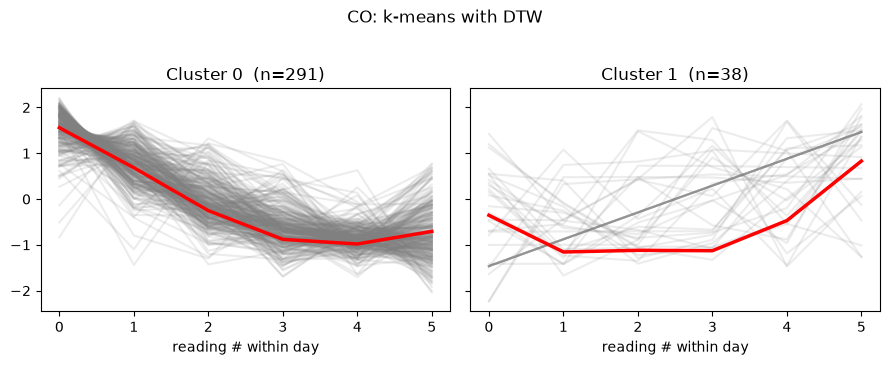

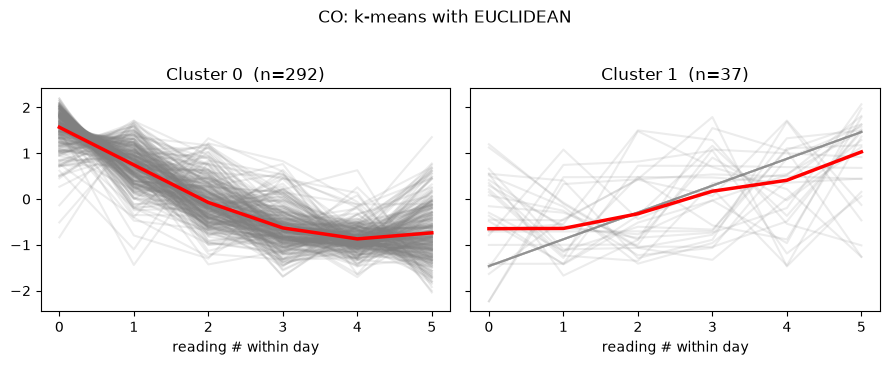

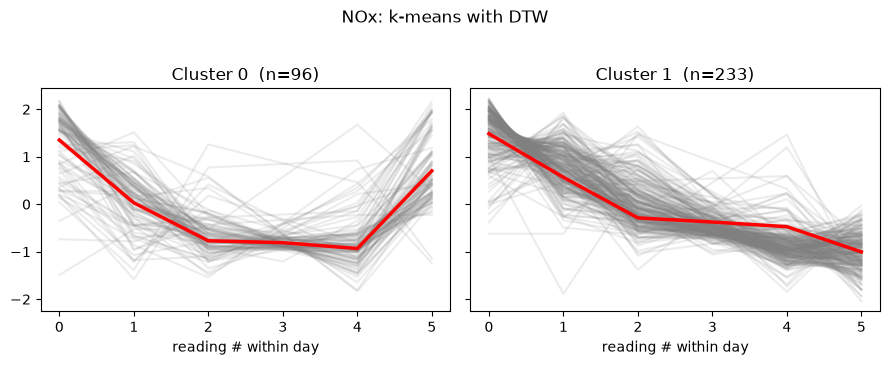

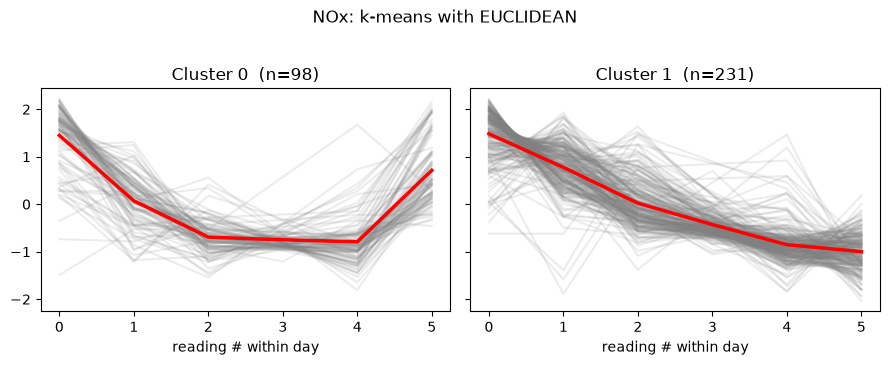

In [ ]:
# 8. Plot
def plot_clusters(sig, metric):
    Xs, km, lab = X[sig], models[(sig, metric)], labels[(sig, metric)]
    fig, axes = plt.subplots(1, K, figsize=(4.5 * K, 3.5), sharey=True)
    for c, ax in enumerate(np.atleast_1d(axes)):
        for series in Xs[lab == c]:
            ax.plot(series.ravel(), color='gray', alpha=0.15)
        ax.plot(km.cluster_centers_[c].ravel(), color='red', linewidth=2.5)
        ax.set_title(f'Cluster {c}  (n={int((lab == c).sum())})')
        ax.set_xlabel('reading # within day')
    fig.suptitle(f'{sig}: k-means with {metric.upper()}', y=1.03)
    plt.tight_layout()
    plt.show()

for sig in X:
    for metric in ['dtw', 'euclidean']:
        plot_clusters(sig, metric)

In [ ]:
# 9. Evaluation 
rows = []
for sig in X:
    lab_d, lab_e = labels[(sig, 'dtw')], labels[(sig, 'euclidean')]
    rows.append({
        'Signal': sig,
        'Silhouette DTW (own metric)':     silhouette_score(X[sig], lab_d, metric='dtw'),
        'Silhouette Euclid (own metric)':  silhouette_score(X[sig], lab_e, metric='euclidean'),
        'DTW labels scored by Euclid':     silhouette_score(X[sig], lab_d, metric='euclidean'),
        'Euclid labels scored by DTW':     silhouette_score(X[sig], lab_e, metric='dtw'),
        'Agreement (adjusted Rand index)': adjusted_rand_score(lab_d, lab_e),
    })

print(pd.DataFrame(rows).set_index('Signal').round(3).T)

Signal                              CO    NOx
Silhouette DTW (own metric)      0.622  0.414
Silhouette Euclid (own metric)   0.611  0.395
DTW labels scored by Euclid      0.608  0.400
Euclid labels scored by DTW      0.625  0.404
Agreement (adjusted Rand index)  0.981  0.878


**Answer:**
**DTW vs Euclidean:** The two methods gave almost identical clusters. The adjusted Rand index was 0.981 for CO and 0.878 for NOx, cluster sizes differed by only 1-2 days, and the silhouette scores were nearly the same (CO 0.622 vs 0.611, NOx 0.414 vs 0.395), so neither was clearly better.

The main visible difference is the center of CO's small, irregular cluster, which DTW and Euclidean average differently. The similarity is expected: each series has only 6 points, so DTW has almost no room to shift or stretch the series, and it behaves much like Euclidean distance. DTW would matter more for longer series, or for days with the same shape shifted in time.

## Timeseries Mining
In a time series, some patterns repeat often, and some are unusual.

- Motifs → patterns that repeat frequently.
- Discords → patterns that are unusual or rare.

To find them efficiently, we use the Matrix Profile, which is a distance table that tells us how similar each small sequence is to all the others.

- Low values in the Matrix Profile → that subsequence has a close match → likely a motif.
- High values in the Matrix Profile → that subsequence has no similar match → likely a discord.

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 6 (2pt)

- Find motifs and discords from the two time series signals.

 
Hint: You can explore the stumpy library for this: https://stumpy.readthedocs.io/en/latest/Tutorial_STUMPY_Basics.html
 </div>

In [ ]:
#YOUR CODE HERE
# 1. Setup 
    # Window length : weekly , 7 days 

import stumpy   #compute matrix profile for a time series 

M = 7   

series = {
    'CO':  air_daily['PT08.S1(CO)'],
    'NOx': air_daily['NOx(GT)'],
}

# 2. Check if there's no invalid data 
print("length = Number of daily values, one per day| Subsequence = Number of 7 days window = 389-7+1 = 383 ")
for name, s in series.items():
    print(name, "| length:", len(s), "| Invalid Value:", int(s.isna().sum()),
          "| subsequences:", len(s) - M + 1)


# 3. Compute matrix profile 
print("\n Matrix profile....\n")
mp = {name: stumpy.stump(s.values.astype(float), m=M) for name, s in series.items()}    # 383 rows
print ("Mp data = \n")
print(mp)
profile = {}
for name in mp:
    p = mp[name][:, 0].astype(float)
    p[~np.isfinite(p)] = np.nan         
    profile[name] = p
    print(name, "| min:", np.nanmin(p).round(3), "| max:", np.nanmax(p).round(3))

length = Number of daily values, one per day| Subsequence = Number of 7 days window = 389-7+1 = 383 
CO | length: 389 | Invalid Value: 0 | subsequences: 383
NOx | length: 389 | Invalid Value: 0 | subsequences: 383

 Matrix profile....

Mp data = 

{'CO': mparray([[0.4197910041263022, 323, -1, 323],
         [0.5876972709862907, 360, -1, 360],
         [0.7292893487931258, 361, -1, 361],
         ...,
         [1.1658139969947101, 313, 313, -1],
         [1.0882562559209188, 314, 314, -1],
         [0.7838307248080877, 377, 377, -1]], shape=(383, 4), dtype=object), 'NOx': mparray([[1.7943534654907531, 177, -1, 177],
         [1.9404803533194455, 178, -1, 178],
         [1.9311285516928522, 51, -1, 51],
         ...,
         [1.0500937776742636, 313, 313, -1],
         [0.7083584461676422, 335, 335, -1],
         [0.5130190097763586, 349, 349, -1]], shape=(383, 4), dtype=object)}
CO | min: 0.214 | max: 2.354
NOx | min: 0.0 | max: 1.94


In [ ]:
# Nox min 0.0 analaysis 
    # Nox is exactly 0.0 min, highly unlikely in noisy data, why ?
p = profile['NOx']
i = int(np.nanargmin(p))
j = int(mp['NOx'][i, 1])
print("Window 1:", series['NOx'].index[i].date(), series['NOx'].values[i:i+M].round(1))
print("Window 2:", series['NOx'].index[j].date(), series['NOx'].values[j:j+M].round(1))
print("Windows with distance < 0.05:", int((p < 0.05).sum()))

Window 1: 2005-01-20 [409.1 598.1 542.3 236.2 204.  147.4 162.7]
Window 2: 2005-02-23 [278.2 381.  338.4 226.6 209.7 160.2 182.7]
Windows with distance < 0.05: 0


**Finding:**
1. Both straight lines  are at regular steps i.e., 13.3 and 3.4 
2. 4 such window with distance less than 0.05

**Reason** : Interpolated data 'air_daily' used can be one reason. straight line addition in the invalid data 
**Possible fix:** Remove the interpolation and replace it with NaN, so that stumpy escape those window with unavailable part Nan

In [ ]:
# days that had NO valid NOx reading (these were interpolated in Task 1)
valid_per_day = air_raw['NOx(GT)'].groupby(air_raw.index).count()
filled = (valid_per_day == 0).reindex(air_daily.index, fill_value=False)
print("Interpolated NOx days:", int(filled.sum()))

# longest filled stretch
run_id = (filled != filled.shift()).cumsum()
print("Longest run of filled days:", int(filled.groupby(run_id).sum().max()))

# NOx with the filled days blanked out
series['NOx'] = air_daily['NOx(GT)'].mask(filled)

# recompute the profile
mp['NOx'] = stumpy.stump(series['NOx'].values.astype(float), m=M)
p = mp['NOx'][:, 0].astype(float)
p[~np.isfinite(p)] = np.nan
profile['NOx'] = p
print("NOx | valid windows:", int(np.isfinite(p).sum()), "of", len(p),
      "| min:", np.nanmin(p).round(3), "| max:", np.nanmax(p).round(3))

Interpolated NOx days: 34
Longest run of filled days: 6
NOx | valid windows: 275 of 383 | min: 0.367 | max: 2.055


**Note:**Days with no valid Nox reading were now excluded (275 out 383 valid)

In [ ]:
# nearest-match index for every window (column 1 of the stump output)
nn = {name: mp[name][:, 1].astype(int) for name in series}

def pick_motifs(p, nn, m, k=3):
    """Lowest profile values, as pairs of non-overlapping windows."""
    order = np.argsort(np.where(np.isnan(p), np.inf, p))
    picks, used = [], []
    for i in order:
        if np.isnan(p[i]):
            break
        j = int(nn[i])
        if j < 0 or abs(i - j) < m:                       # overlapping pair
            continue
        if any(abs(i - u) < m or abs(j - u) < m for u in used):
            continue                                       # already covered by an earlier motif
        picks.append(int(i)); used += [int(i), j]
        if len(picks) == k:
            break
    return picks

def pick_discords(p, m, k=3):
    """Highest profile values, blanking +/- m days around each pick."""
    p = p.copy(); picks = []
    for _ in range(k):
        if np.all(np.isnan(p)):
            break
        i = int(np.nanargmax(p)); picks.append(i)
        p[max(0, i - m): i + m + 1] = np.nan
    return picks

results = {}
for name in series:
    idx, p = series[name].index, profile[name]
    results[name] = {'motifs':   pick_motifs(p, nn[name], M),
                     'discords': pick_discords(p, M)}
    print(f"\n{name}")
    for i in results[name]['motifs']:
        j = nn[name][i]
        print(f"  motif   : {idx[i].date()} <-> {idx[j].date()}  (distance {p[i]:.3f})")
    for i in results[name]['discords']:
        print(f"  discord : {idx[i].date()} to {idx[i+M-1].date()}  (distance {p[i]:.3f})")


CO
  motif   : 2004-07-15 <-> 2004-06-24  (distance 0.214)
  motif   : 2004-08-14 <-> 2004-10-02  (distance 0.222)
  motif   : 2004-09-23 <-> 2004-04-23  (distance 0.326)
  discord : 2004-12-23 to 2004-12-29  (distance 2.354)
  discord : 2004-05-11 to 2004-05-17  (distance 2.219)
  discord : 2005-01-22 to 2005-01-28  (distance 1.804)

NOx
  motif   : 2005-02-23 <-> 2005-01-20  (distance 0.367)
  motif   : 2004-06-28 <-> 2005-03-14  (distance 0.384)
  motif   : 2004-05-10 <-> 2004-07-12  (distance 0.457)
  discord : 2004-03-12 to 2004-03-18  (distance 2.055)
  discord : 2004-10-29 to 2004-11-04  (distance 1.883)
  discord : 2005-01-01 to 2005-01-07  (distance 1.780)


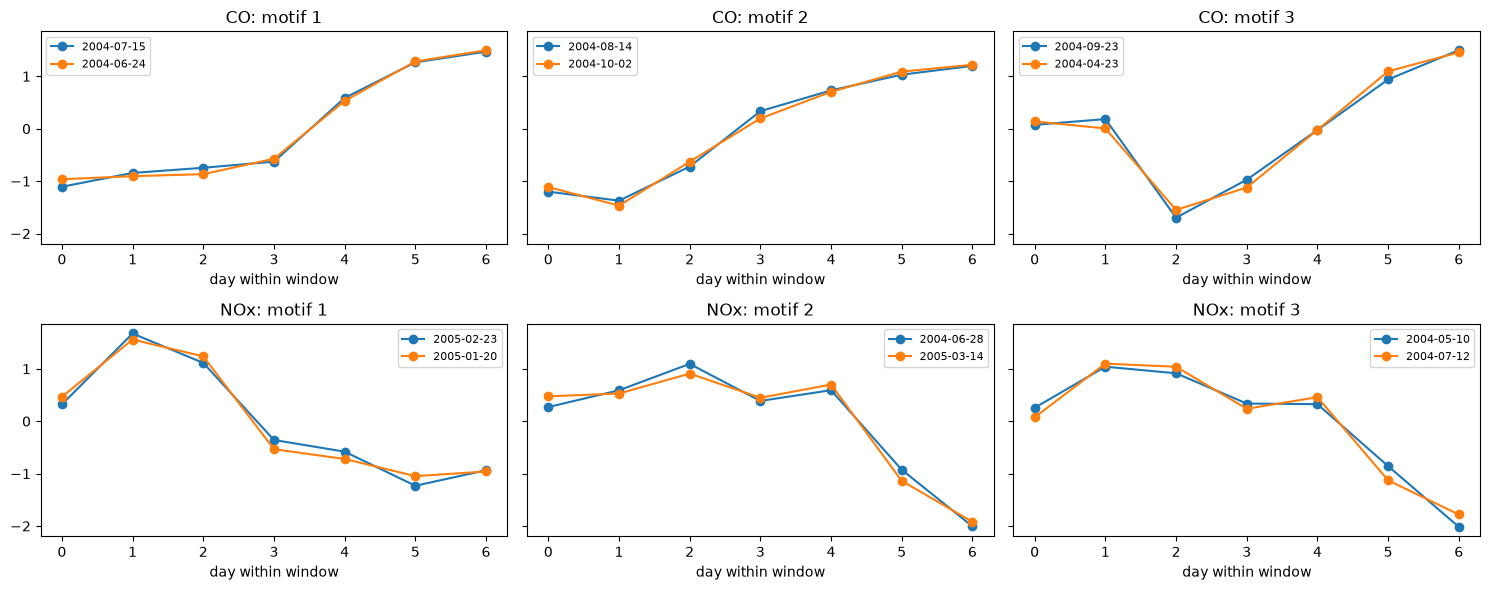

In [ ]:
def znorm(x):
    return (x - x.mean()) / x.std()

fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharey=True)
for r, name in enumerate(series):
    s = series[name]
    for c, i in enumerate(results[name]['motifs'][:3]):
        j = nn[name][i]
        axes[r, c].plot(znorm(s.values[i:i+M]), marker='o', label=str(s.index[i].date()))
        axes[r, c].plot(znorm(s.values[j:j+M]), marker='o', label=str(s.index[j].date()))
        axes[r, c].set_title(f'{name}: motif {c+1}')
        axes[r, c].set_xlabel('day within window')
        axes[r, c].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Finding and Conclusion:

**Motifs (repeating patterns):**
- **CO** has very close matches (distances 0.21-0.33). Most are a flat or dipping start followed by a rise shows strong upward trend, most likely reflects the ordinary week days pattern. However,  The third motif is bit different, it falls on day 2 then recover the upward trend. This occur in different months, April and Septemember.  
- **NOx** matches are looser (0.37-0.46): an early peak followed by a decline. One pair joins a window before the September 2004 level shift with one after it, so the same weekly shape recurs at very different levels.

**Discords (unusual patterns):**
- **CO:** 23-29 Dec 2004 (2.35), 11-17 May 2004 (2.22), 22-28 Jan 2005 (1.80)
- **NOx:** 12-18 Mar 2004 (2.06), 29 Oct-4 Nov 2004 (1.88), 1-7 Jan 2005 (1.78)

Two discords fall around the year-end period, which may reflect changed activity, but the cause is hard to verify this is because a discord shows that a week has an unusual shape, not why. It could be a real event, a sensor glitch or an effect of the cleaning.


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task 7: Optional

- Transform the signals using any time-series transformation method of your choice(e.g SAX, PAX..). The method should be implemented from scratch.
 